# 02 · Exploração e análise do painel

Comparamos os níveis, a volatilidade e a evolução temporal da inflação alimentar. No fim, examinamos a associação contemporânea com os indicadores climáticos e económicos. Os cálculos estão em `scripts/analise_resultados.py` e `scripts/exploracao.py`; os gráficos, em `scripts/graficos.py`.

A inflação alimentar média do painel é 0,411 por mês na escala logarítmica aproximada em percentagem. A mediana é 0,336, e 33,9% das observações têm variação negativa. A média positiva ao longo do período coexiste, por isso, com muitos meses de queda de preços.

A Nigéria tem a média nacional mais elevada (1,20); o Japão tem a mais baixa (0,13). A maior parte da variabilidade da resposta, 97,5%, ocorre dentro dos países ao longo do tempo. As secções seguintes mostram os valores que sustentam estas comparações.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

pasta_atual = Path.cwd().resolve()
raiz = pasta_atual if (pasta_atual / "scripts").is_dir() else pasta_atual.parent
assert (raiz / "scripts").is_dir(), "Abra o Jupyter na pasta Trabalho ou em notebooks/."
if str(raiz / "scripts") not in sys.path:
    sys.path.insert(0, str(raiz / "scripts"))
from preparacao import ler_painel
from estilo_iscte import configurar, tabela, csv, dirs, pt, Y, VARS, VAR_LABELS, UNITS

configurar()
pasta_dados = raiz / "dados" / "originais"
dados = ler_painel(pasta_dados)
from exploracao import (
    estatisticas_globais,
    estatisticas_por_pais,
    evolucao_agregada,
    decompor_dispersao,
    anomalias_anuais,
)
from graficos import (
    trajetorias_por_pais,
    distribuicoes_nacionais,
    evolucao_da_media,
    dispersao_entre_dentro,
    mapa_anomalias,
)

tabelas, graficos = dirs(raiz, "02_exploracao")

## 1. Estatísticas descritivas

Cada observação país–mês tem igual peso. O painel é equilibrado, pelo que cada país contribui com 311 meses. Unidades diferentes não são comparadas diretamente pela dimensão numérica do desvio padrão.

In [2]:
descritivas = estatisticas_globais(dados, VARS)
tabela(
    descritivas.drop(columns="coluna"),
    "Tabela 2.1 · Estatísticas globais",
    formatos={"N": lambda valor: pt(valor, 0)},
)
csv(descritivas, tabelas / "01_estatisticas_descritivas.csv")
csv(estatisticas_por_pais(dados), tabelas / "02_inflacao_por_pais.csv")

Variável,Unidade,N,Média,DP,Mínimo,Q1,Mediana,Q3,Máximo
Inflação alimentar,100 × Δ ln IPC; aprox. %/mês,4 665,"0,411","1,782","-10,135","-0,271","0,336","1,079","11,880"
Anomalia térmica,°C,4 665,"0,177","0,694","-2,843","-0,243","0,157","0,570","2,850"
Défice hídrico de 3 meses,desvios padrão,4 665,"0,097","0,935","-4,171","-0,501","0,148","0,723","3,247"
Log PIB real por habitante (t−1),log natural,4 665,"8,936","1,234","6,886","7,876","8,956","9,941","10,789"
Peso agrícola no PIB (t−1),pontos percentuais do PIB,4 665,"15,436","12,978","0,825","2,961","12,171","26,089","47,969"
Calor × log PIB,°C × log PIB,4 665,"1,653","6,534","-28,712","-2,070","1,360","4,961","30,649"
Calor × peso agrícola,°C × p.p. do PIB,4 665,"2,172","12,797","-99,524","-1,590","0,940","5,102","110,329"


### Análise da distribuição global

O desvio padrão da inflação é 1,78, mais de quatro vezes a média. Os extremos vão de −10,13 no Benim, em fevereiro de 2022, a 11,88 na Nigéria, em julho de 2005. São valores mensais logarítmicos, não taxas homólogas anuais.

A amplitude global combina diferenças de volatilidade e episódios de variação acentuada. Como cerca de um terço dos meses apresenta valores negativos, uma transformação logarítmica adicional da taxa não seria admissível para toda a amostra. Os logaritmos já foram usados no IPC que dá origem à resposta.

## 2. Trajetórias por país

Todos os painéis usam a mesma escala. Azul: taxa mensal. Laranja: média móvel retrospetiva dos últimos 12 meses, sem usar meses futuros. O suavizador perde os primeiros 11 meses e não constitui ajuste sazonal.

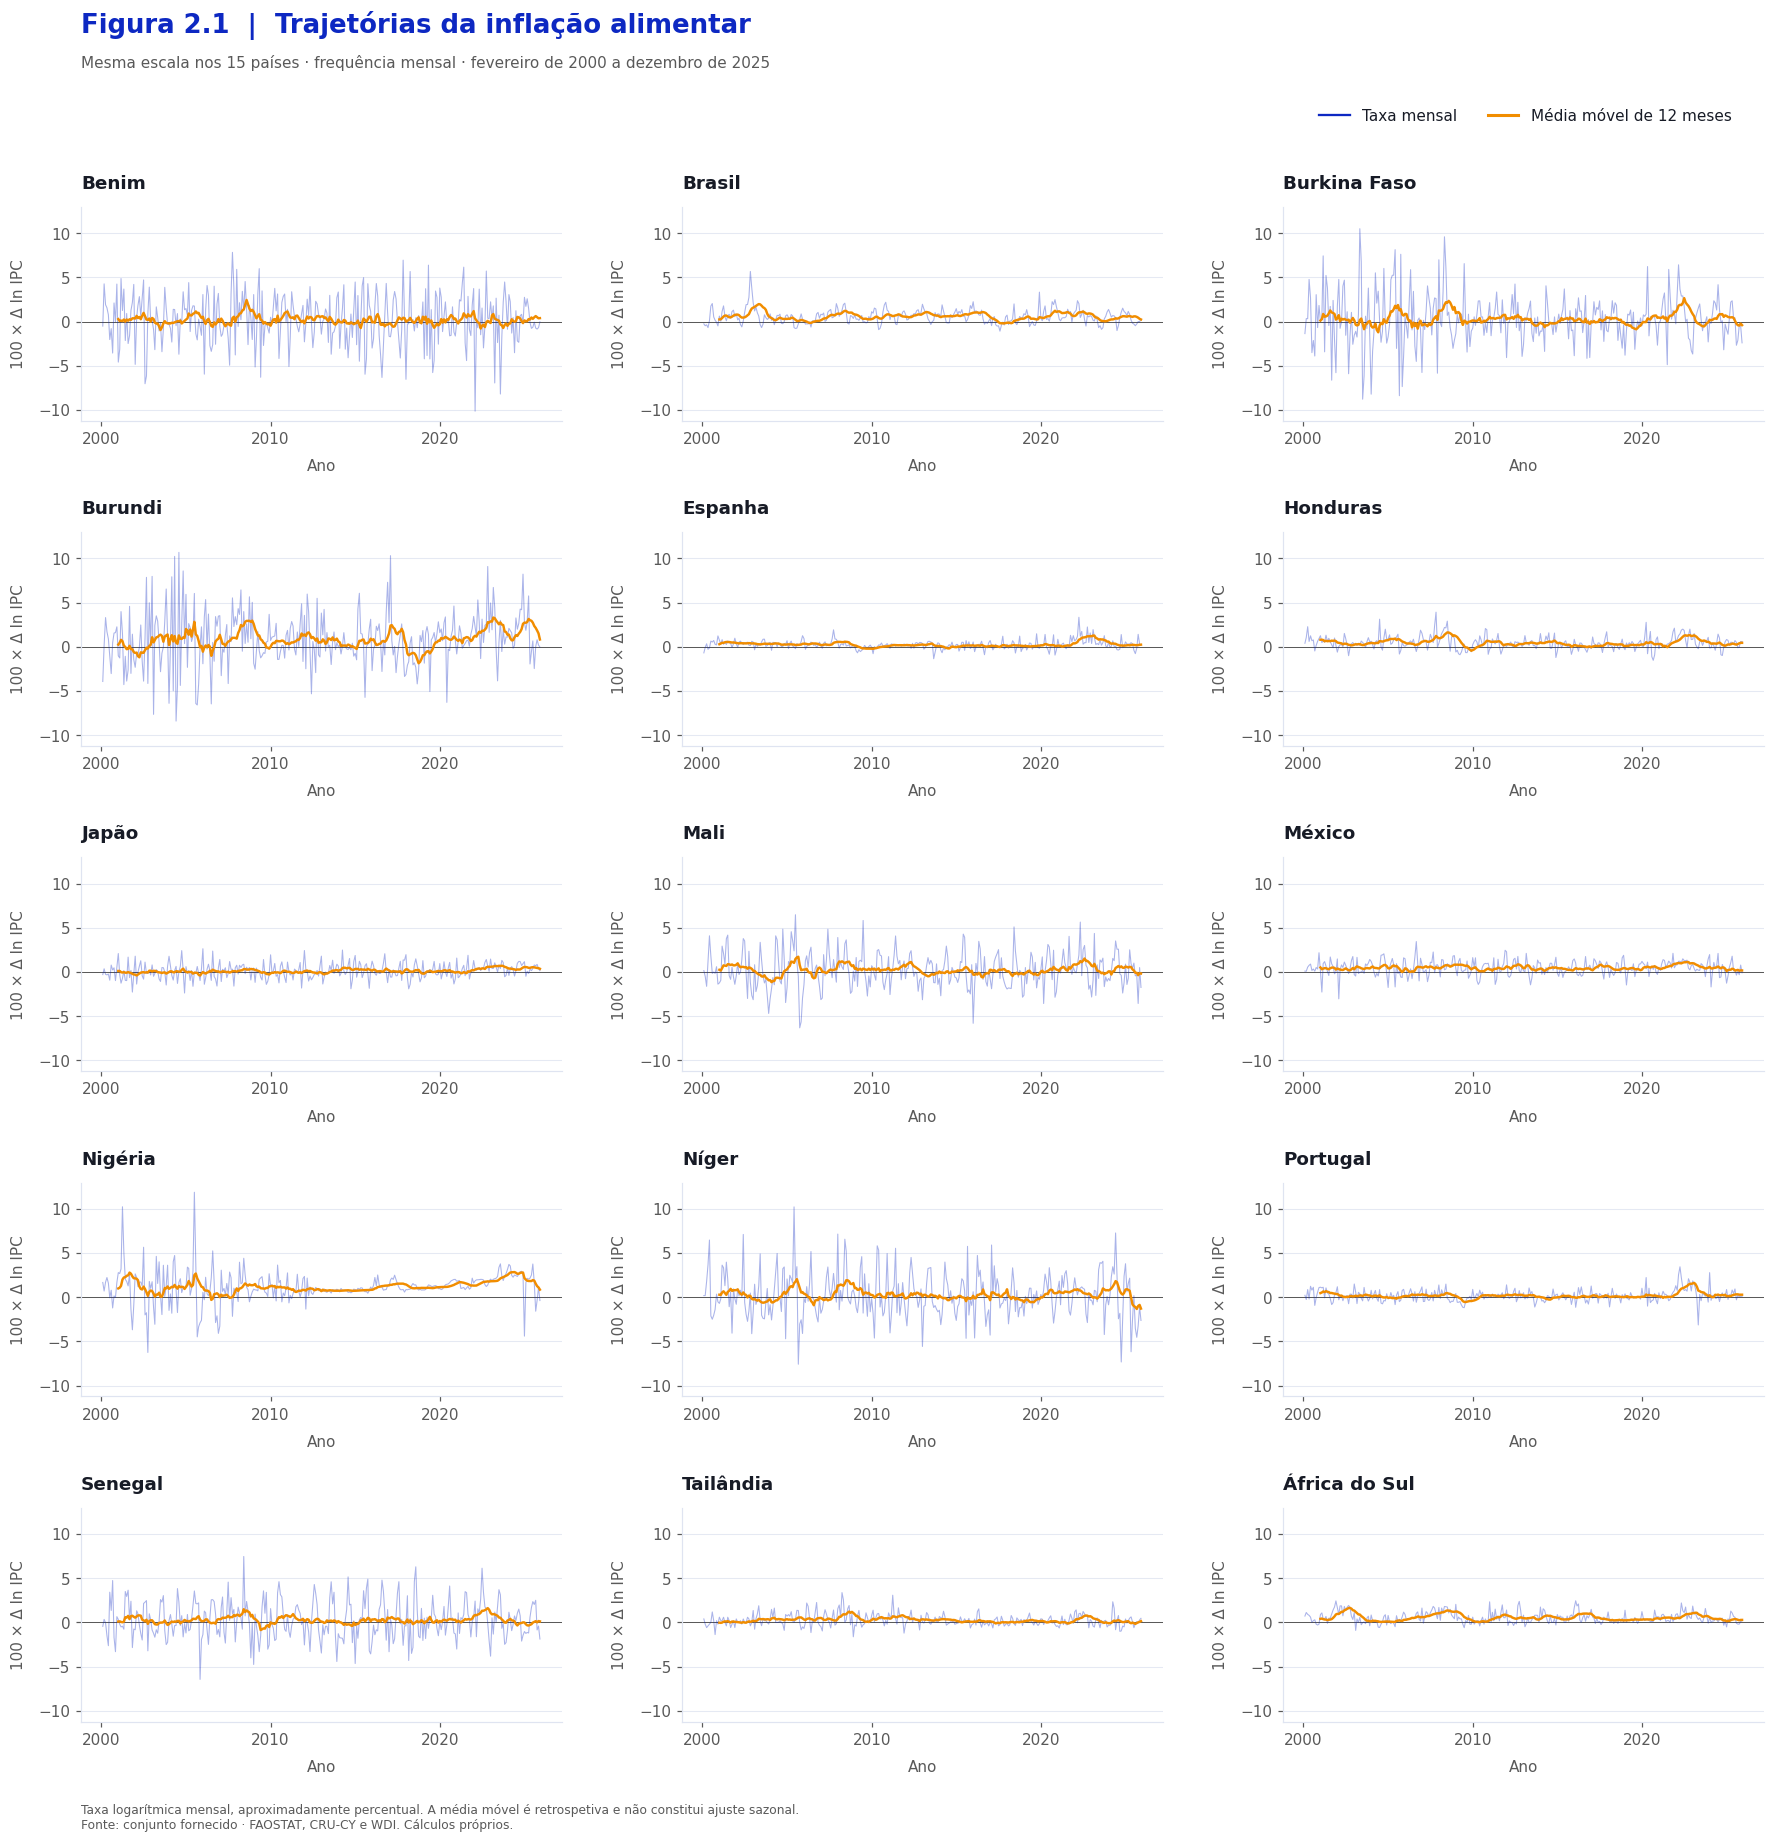

In [3]:
trajetorias_por_pais(dados, graficos)
medias = dados.groupby("pais")[Y].mean().sort_values()

### Análise das trajetórias nacionais

A diferença entre a inflação média da Nigéria (1,20) e a do Japão (0,13) é 1,08 pontos logarítmicos aproximados por mês. Portugal apresenta uma média de 0,19, também abaixo da média do painel.

Burundi combina uma média elevada (0,84) com o maior desvio padrão nacional (2,99). No Brasil, a média é 0,58 e o desvio padrão é 0,81. Trajetórias com médias relativamente próximas podem, assim, ter volatilidades muito diferentes. A suavização de 12 meses ajuda a localizar fases persistentes; os picos individuais continuam visíveis na linha mensal.

## 3. Distribuições nacionais

As caixas mostram Q1, mediana e Q3; os bigodes seguem a regra de 1,5 × IQR. O ponto azul é a média. Os pontos exteriores são omitidos apenas do gráfico: permanecem no painel e nas estatísticas. As caixas não são intervalos de confiança.

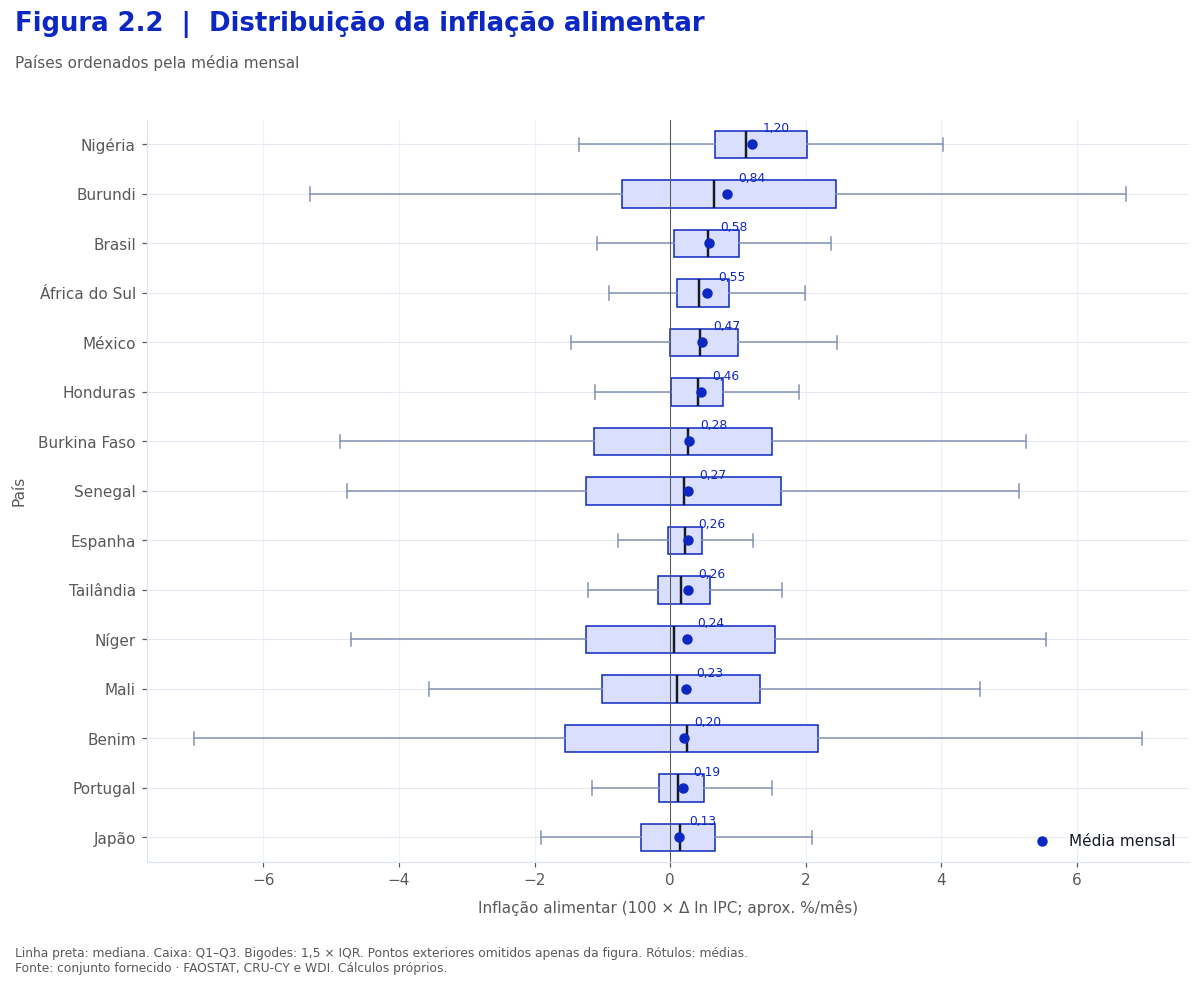

In [4]:
distribuicoes_nacionais(dados, graficos)

### Análise das distribuições por país

O Benim tem uma média de apenas 0,20, mas um desvio padrão de 2,83; em Espanha os valores são 0,26 e 0,51, respetivamente. Uma média baixa não implica estabilidade de preços ao longo dos meses.

No Níger, 47,3% dos meses têm inflação negativa e o desvio padrão é 2,50. Na Nigéria, apenas 11,9% dos meses são negativos. A posição e a largura das caixas refletem, portanto, experiências distintas de frequência das quedas e amplitude das variações. Os limites dos eixos são iguais entre países; os pontos exteriores foram omitidos apenas desta figura.

## 4. Evolução da média transversal

Comparam-se a média e a mediana dos países em cada mês. Os países não são ponderados pela população ou despesa alimentar: esta agregação não é uma taxa oficial de inflação mundial.

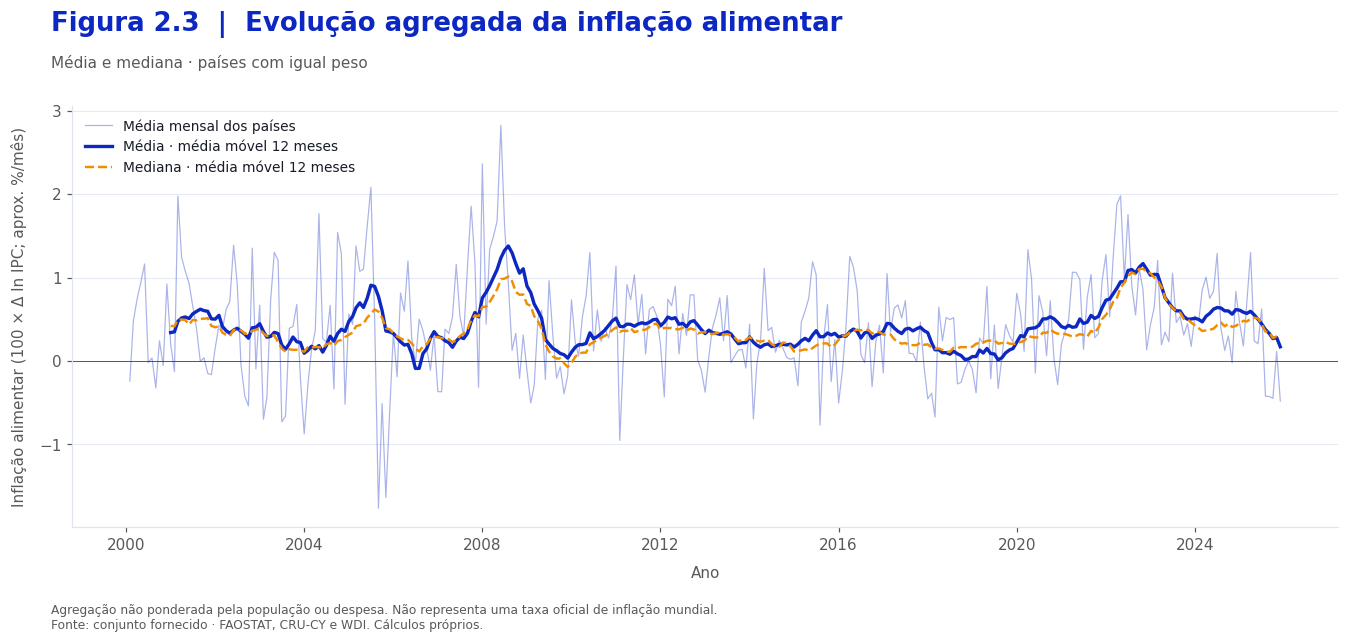

In [5]:
mensal = evolucao_agregada(dados)
evolucao_da_media(mensal, graficos)
csv(mensal.reset_index(), tabelas / "03_evolucao_agregada.csv")
pico = mensal["mean"].idxmax()

In [6]:
from analise_resultados import comparar_periodos

periodos, periodos_pais = comparar_periodos(dados)
tabela(periodos, "Tabela 2.2 · Inflação mensal por período")
comparacao_pais = periodos_pais.rename(
    columns={
        "pais": "País",
        "mudanca_2020_2025_vs_2010_2019": "Diferença recente (p.p. aprox.)",
    }
)
tabela(comparacao_pais, "Tabela 2.3 · Comparação dos períodos por país")
csv(periodos, tabelas / "06_inflacao_por_periodo.csv")
csv(periodos_pais, tabelas / "07_periodos_por_pais.csv")

periodo,media,mediana,desvio_padrao,observacoes
2000–2009,"0,422","0,324","2,075","1 785,000"
2010–2019,"0,297","0,263","1,533","1 800,000"
2020–2025,"0,582","0,469","1,624","1 080,000"


País,2000–2009,2010–2019,2020–2025,Diferença recente (p.p. aprox.)
Benim,"0,277","0,128","0,206","0,078"
Brasil,"0,567","0,583","0,600","0,017"
Burkina Faso,"0,348","0,091","0,486","0,395"
Burundi,"0,722","0,509","1,607","1,098"
Espanha,"0,282","0,116","0,448","0,332"
Honduras,"0,565","0,312","0,540","0,229"
Japão,"-0,009","0,119","0,360","0,241"
Mali,"0,285","0,092","0,380","0,288"
México,"0,469","0,419","0,573","0,155"
Nigéria,"1,069","0,993","1,775","0,783"


### Análise da evolução por períodos

A média mensal passa de 0,422 em 2000–2009 para 0,297 em 2010–2019 e sobe para 0,582 em 2020–2025. A subida mais recente face a 2010–2019 é 0,285 pontos logarítmicos aproximados por mês. A tabela compara médias de taxas mensais; esses valores não representam inflação anual acumulada.

O aumento não se distribui igualmente. Burundi passa de 0,509 para 1,607, e a Nigéria de 0,993 para 1,775. Em Portugal, a média sobe de 0,098 para 0,431; em Espanha, de 0,116 para 0,448. A Tailândia é o único país com redução nesta comparação, de 0,243 para 0,169. A fase recente tem maior inflação média em 14 dos 15 países, mas a dimensão da alteração varia substancialmente.

Os períodos têm durações diferentes: 119 meses em 2000–2009, 120 em 2010–2019 e 72 em 2020–2025. Cada país tem o mesmo peso dentro de cada período. A comparação localiza mudanças na amostra, sem atribuir a subida a um acontecimento específico.

## 5. Variabilidade entre e dentro dos países

**Entre:** desvio padrão das 15 médias nacionais. **Dentro:** desvio padrão dos desvios face à média do respetivo país. Os denominadores são diferentes; estas medidas não são parcelas aditivas de variância. Cada painel da figura usa a unidade indicada no seu eixo.

Variável,Unidade,DP total,DP entre médias,DP dentro
Inflação alimentar,100 × Δ ln IPC; aprox. %/mês,"1,782","0,291","1,760"
Anomalia térmica,°C,"0,694","0,072","0,691"
Défice hídrico de 3 meses,desvios padrão,"0,935","0,110","0,929"
Log PIB real por habitante (t−1),log natural,"1,234","1,272","0,116"
Peso agrícola no PIB (t−1),pontos percentuais do PIB,"12,978","13,242","2,176"
Calor × log PIB,°C × log PIB,"6,534","0,823","6,485"
Calor × peso agrícola,°C × p.p. do PIB,"12,797","1,768","12,682"


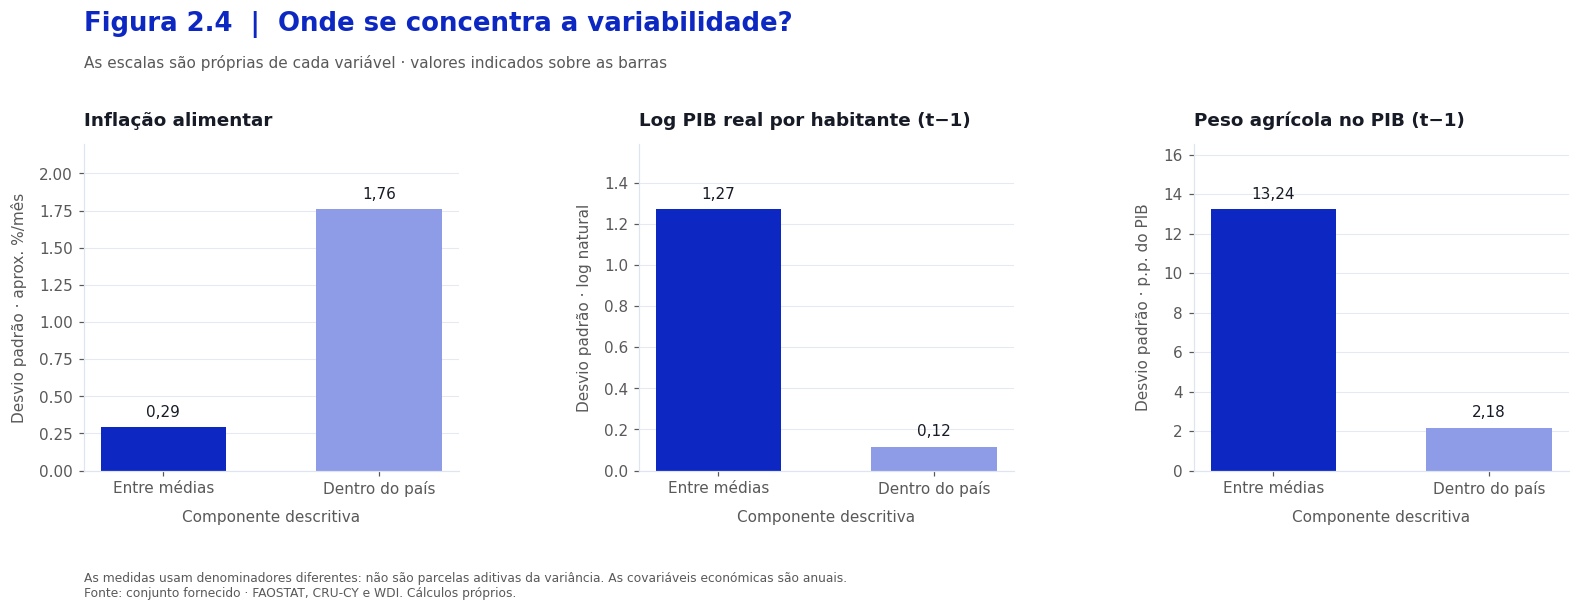

In [7]:
variacao = decompor_dispersao(dados, VARS)
tabela(variacao.drop(columns="coluna"), "Tabela 2.4 · Variabilidade entre e dentro")
csv(variacao, tabelas / "04_variabilidade_entre_dentro.csv")
dispersao_entre_dentro(variacao, graficos)

In [8]:
from analise_resultados import decompor_variancia

partes_variancia = decompor_variancia(dados, VARS)
tabela(partes_variancia, "Tabela 2.5 · Percentagens da soma de quadrados total")
csv(partes_variancia, tabelas / "08_partes_da_variancia.csv")

Variável,Dentro (%),Entre (%)
Inflação alimentar,"97,504","2,496"
Anomalia térmica,"99,009","0,991"
Défice hídrico de 3 meses,"98,706","1,294"
Log PIB real por habitante (t−1),"0,883","99,117"
Peso agrícola no PIB (t−1),"2,811","97,189"
Calor × log PIB,"98,517","1,483"
Calor × peso agrícola,"98,217","1,783"


### Análise da variabilidade entre e dentro

Ao decompor a soma de quadrados, 97,50% da variabilidade da inflação ocorre dentro dos países e 2,50% corresponde a diferenças entre as médias nacionais. A análise da resposta depende sobretudo de explicar oscilações temporais, mesmo existindo diferenças persistentes de nível entre países.

Nas variáveis económicas acontece o inverso: 99,12% da variabilidade do log PIB por habitante e 97,19% da do peso agrícola estão entre países. Os efeitos fixos nacionais retiram essas diferenças persistentes. A estimação dos coeficientes económicos num modelo com efeitos fixos terá de usar a parcela de variação temporal que resta: 0,88% e 2,81%, respetivamente.

As percentagens desta tabela provêm de uma decomposição exata de somas de quadrados, que somam 100%. Os desvios padrão da tabela anterior usam denominadores diferentes e não devem ser somados para obter estas percentagens.

## 6. Evolução das anomalias térmicas

As células representam médias anuais de anomalias mensais face à referência 1991–2020, calculada por país e mês. Fevereiro–dezembro de 2000 contém 11 meses; os outros anos contêm 12. Médias nacionais e anuais podem ocultar extremos locais.

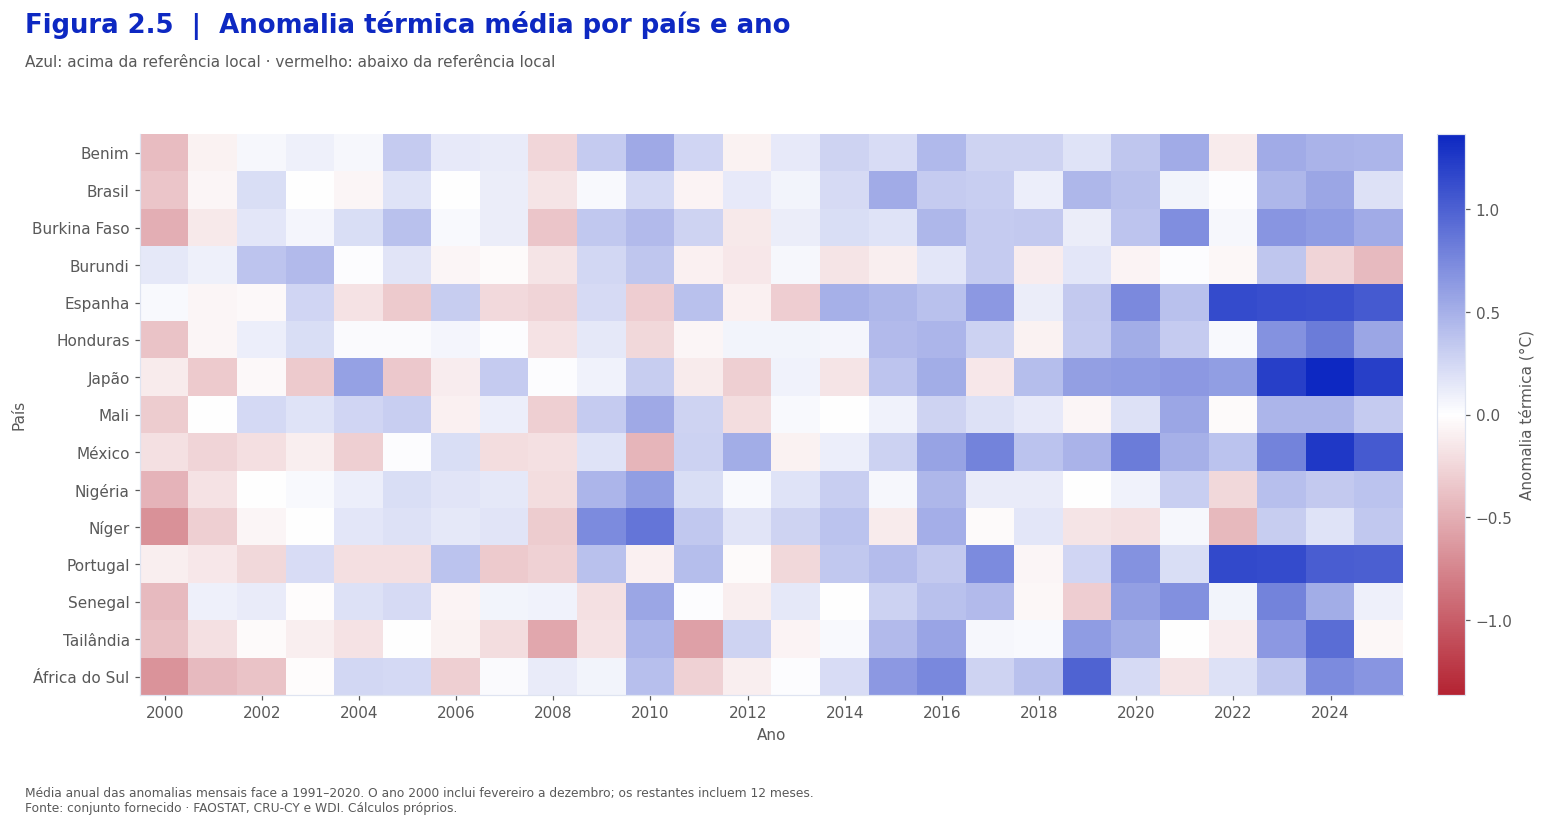

In [9]:
anual = anomalias_anuais(dados)
mapa_anomalias(anual, graficos)
csv(anual.reset_index(), tabelas / "05_anomalias_anuais.csv")

In [10]:
from analise_resultados import comparar_janelas_climaticas

janelas_clima = comparar_janelas_climaticas(dados)
tabela(
    janelas_clima.rename(columns={"pais": "País"}),
    "Tabela 2.6 · Anomalias em duas janelas de cinco anos",
)
csv(janelas_clima, tabelas / "09_janelas_climaticas.csv")

País,2001–2005 (°C),2021–2025 (°C),Diferença (°C)
Japão,"-0,086","1,009","1,095"
Espanha,"-0,068","0,956","1,023"
Portugal,"-0,109","0,904","1,013"
México,"-0,166","0,789","0,955"
Honduras,"0,062","0,490","0,428"
África do Sul,"-0,061","0,354","0,415"
Burkina Faso,"0,132","0,517","0,385"
Tailândia,"-0,096","0,281","0,377"
Senegal,"0,122","0,431","0,308"
Benim,"0,087","0,376","0,288"


### Análise das anomalias térmicas

Entre 2001–2005 e 2021–2025, a anomalia média aumenta em 14 dos 15 países. As maiores diferenças são as do Japão (+1,10 °C), Espanha (+1,02 °C) e Portugal (+1,01 °C). Em Portugal, a média passa de −0,109 °C para +0,904 °C face à referência local de 1991–2020.

Burundi apresenta o resultado contrário: a média desce de +0,216 °C para −0,074 °C, uma diferença de −0,290 °C. Esta exceção deve ser conservada e conferida nos dados e metadados climáticos; o nome do conjunto de dados não justifica impor o mesmo sinal a todos os países.

As duas janelas têm 60 meses por país, o que evita comparar um ano inicial incompleto com um período completo. A diferença de médias entre janelas não é uma estimativa da tendência anual nem um teste de significância do aquecimento. O mapa e a tabela descrevem esta amostra nacional; não representam diretamente a temperatura global.

## 7. Associação exploratória entre clima e inflação

Para responder à segunda questão de investigação, comparamos correlações de Pearson em três escalas: observações brutas, desvios face à média do país, e desvios após retirar as médias de país e de data. A última transformação usa a grelha equilibrada e remove movimentos aditivos comuns de país e de mês–ano. Não ajusta simultaneamente todas as covariáveis, não é um modelo causal e não produz aqui testes de significância.

In [11]:
from analise_resultados import correlacoes_com_inflacao

associacoes = correlacoes_com_inflacao(dados)
tabela(associacoes, "Tabela 2.7 · Correlações contemporâneas com a inflação")
csv(associacoes, tabelas / "10_correlacoes_exploratorias.csv")

Variável,Bruta,Dentro do país,Sem país e data
Anomalia térmica,"-0,028","-0,022","-0,028"
Défice hídrico de 3 meses,"-0,021","-0,020","-0,019"
Log PIB real por habitante (t−1),"-0,029","-0,011","-0,027"
Peso agrícola no PIB (t−1),"0,033","-0,040","-0,038"


A correlação bruta entre anomalia térmica e inflação é −0,028; após retirar os efeitos aditivos de país e data, mantém-se em −0,028. Para o défice hídrico, os valores são −0,021 e −0,019. Estas associações lineares contemporâneas são fracas na amostra. Os dados explorados não sustentam, por si só, a afirmação de que meses mais quentes ou mais secos têm inflação alimentar mensal claramente superior.

O peso agrícola apresenta correlação bruta de +0,033, que passa a −0,040 quando se usam desvios dentro do país. A mudança de sinal mostra que a comparação entre países e a variação temporal dentro de cada país não respondem à mesma pergunta. O valor continua próximo de zero em ambas as escalas.

Temperatura e défice hídrico têm correlação entre si de aproximadamente +0,299. A construção do défice inclui evapotranspiração potencial, relacionada com a temperatura, pelo que parte da informação climática pode sobrepor-se. O passo seguinte é estimar associações condicionais e efeitos desfasados, mantendo o controlo do calendário. Correlações pequenas neste exercício não excluem relações não lineares, desfasadas ou diferentes segundo o contexto económico.